# DX799 Week 4: Logistic Regression and Feature Scaling

## 1. Define financial success and modeling safeguards

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, balanced_accuracy_score, confusion_matrix,
                             ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay,
                             brier_score_loss, log_loss)
SEED=42
path=Path('movies.csv')
if not path.exists():path=Path('/mnt/data/movies.csv')
raw=pd.read_csv(path)
print('Raw shape:',raw.shape)
print('Dataset file:',path)

Raw shape: (18905, 23)
Dataset file: movies.csv


## 2. Reproduce Weeks 1 to 3 dataset restrictions and predictors

In [2]:
df=raw.drop_duplicates(subset=['movie_id']).copy()
df['release_date']=pd.to_datetime(df['release_date'],errors='coerce')
df['release_year']=pd.to_numeric(df['release_year'],errors='coerce')
for name in ['budget','revenue','runtime']:
    df[name]=pd.to_numeric(df[name],errors='coerce')
df=df.loc[(df.budget>0)&(df.revenue>0)&df.release_year.between(1980,2024)&df.runtime.between(40,240)&df.release_date.notna()].copy()
df['budget_m']=df.budget/1e6
df['revenue_m']=df.revenue/1e6
df['gross_to_budget']=df.revenue/df.budget
df['success']=(df.gross_to_budget>=2).astype(int)
parsed_genres=df.genres.fillna('').str.split('|')
df['animation']=parsed_genres.map(lambda g:int('Animation' in g))
df['release_month']=df.release_date.dt.month
for genre in ['Action','Comedy','Drama','Horror']:
    df['genre_'+genre.lower()]=parsed_genres.map(lambda g:int(genre in g))
for month in range(2,13):df[f'month_{month}']=(df.release_month==month).astype(int)
features=['budget_m','runtime','release_year','animation','genre_action','genre_comedy','genre_drama','genre_horror']+[f'month_{i}' for i in range(2,13)]
tr,te=train_test_split(np.arange(len(df)),test_size=.2,random_state=SEED)
train,test=df.iloc[tr].copy(),df.iloc[te].copy()
X_train,X_test=train[features],test[features]
y_train,y_test=train.success,test.success
print(f'Filtered movies: {len(df):,}; train: {len(train):,}; test: {len(test):,}')
print(f'Financial success share overall: {df.success.mean():.1%}; training: {y_train.mean():.1%}; test: {y_test.mean():.1%}')
print('Animation movies:',int(df.animation.sum()),'; predictors:',len(features))
print('Success threshold: worldwide gross >= twice the reported production budget')
print(df[['budget_m','revenue_m','gross_to_budget']].describe(percentiles=[.25,.5,.75,.9,.95]).round(2).to_string())

Filtered movies: 7,079; train: 5,663; test: 1,416
Financial success share overall: 43.6%; training: 43.7%; test: 43.1%
Animation movies: 376 ; predictors: 19
Success threshold: worldwide gross >= twice the reported production budget
       budget_m  revenue_m  gross_to_budget
count   7079.00    7079.00          7079.00
mean      33.54      90.64           358.46
std       43.70     181.95         29201.10
min        0.00       0.00             0.00
25%        8.00       5.91             0.55
50%       19.00      26.81             1.61
75%       40.00      92.85             3.49
90%       80.00     233.96             6.88
95%      125.00     389.98            10.54
max      658.80    2923.71       2456760.00


## 3. Exploratory data analysis: class balance and monetary distribution


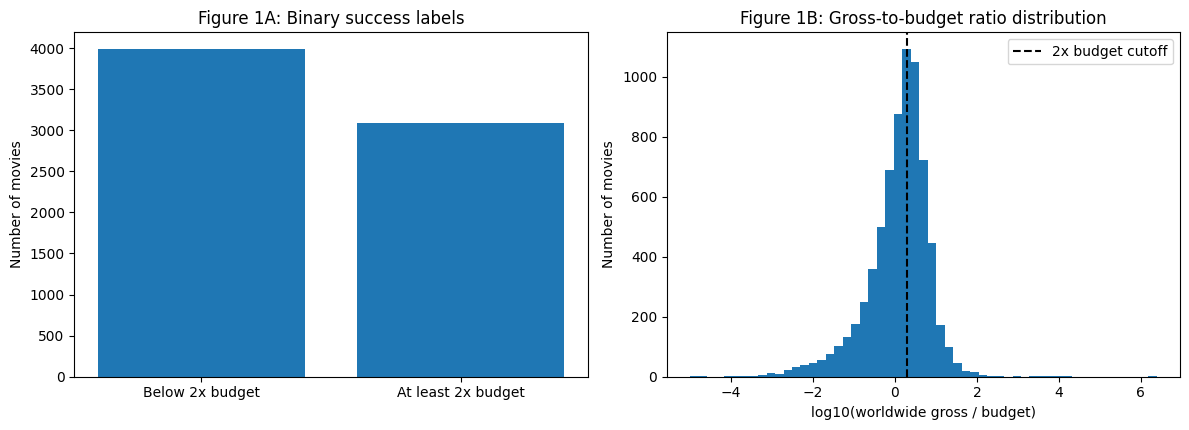

In [3]:
fig,ax=plt.subplots(1,2,figsize=(12,4.4))
counts=df.success.value_counts().reindex([0,1],fill_value=0)
ax[0].bar(['Below 2x budget','At least 2x budget'],counts.values)
ax[0].set(title='Figure 1A: Binary success labels',ylabel='Number of movies')
ax[1].hist(np.log10(df.gross_to_budget.clip(lower=1e-5)),bins=55)
ax[1].axvline(np.log10(2),linestyle='--',color='black',label='2x budget cutoff')
ax[1].set(title='Figure 1B: Gross-to-budget ratio distribution',xlabel='log10(worldwide gross / budget)',ylabel='Number of movies')
ax[1].legend()
plt.tight_layout();plt.show()

## 4. Why feature scaling matters for logistic regression

Unscaled L2: best C=100, mean CV ROC-AUC=0.608


Scaled L2: best C=0.01, mean CV ROC-AUC=0.609


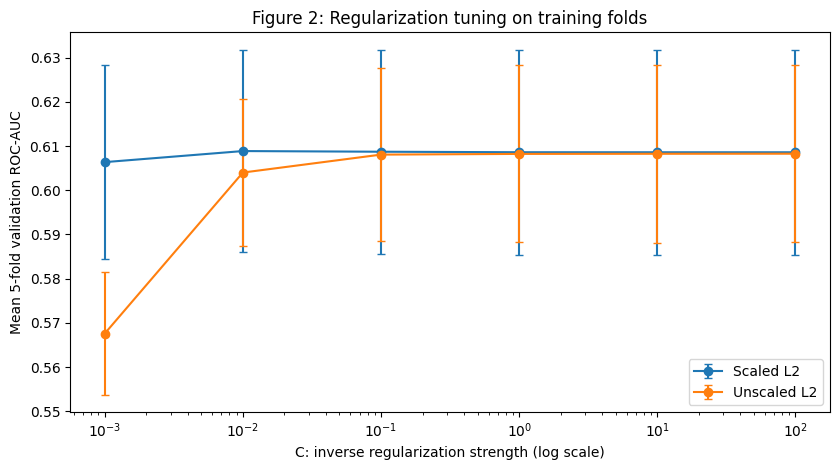

In [4]:
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=SEED)
C_VALUES=[.001,.01,.1,1,10,100]
scenarios={
    'Unscaled L2':Pipeline([('clf',LogisticRegression(max_iter=6000,solver='liblinear',random_state=SEED))]),
    'Scaled L2':Pipeline([('scaler',StandardScaler()),('clf',LogisticRegression(max_iter=6000,solver='liblinear',random_state=SEED))])
}
tuned={}; tuning_frames=[]
for name,pipe in scenarios.items():
    gs=GridSearchCV(pipe,{'clf__C':C_VALUES},scoring='roc_auc',cv=cv,n_jobs=1,return_train_score=True)
    gs.fit(X_train,y_train)
    tuned[name]=gs.best_estimator_
    temp=pd.DataFrame(gs.cv_results_)[['param_clf__C','mean_test_score','std_test_score','mean_train_score']].copy()
    temp['scenario']=name
    tuning_frames.append(temp)
    print(f'{name}: best C={gs.best_params_["clf__C"]}, mean CV ROC-AUC={gs.best_score_:.3f}')
tuning=pd.concat(tuning_frames,ignore_index=True)
fig,ax=plt.subplots(figsize=(8.5,4.8))
for name,group in tuning.groupby('scenario'):
    ax.errorbar(group['param_clf__C'].astype(float),group.mean_test_score,yerr=group.std_test_score,marker='o',capsize=3,label=name)
ax.set_xscale('log')
ax.set(title='Figure 2: Regularization tuning on training folds',xlabel='C: inverse regularization strength (log scale)',ylabel='Mean 5-fold validation ROC-AUC')
ax.legend();plt.tight_layout();plt.show()

## 5. Evaluate predictive accuracy on the reserved test sample

Positive label: worldwide revenue >= 2x production budget
Evaluation threshold: 0.50
             Accuracy  Balanced accuracy  Precision  Recall      F1  ROC-AUC  Average precision  Brier loss
Model                                                                                                      
Unscaled L2    0.6031             0.5715     0.5668  0.3404  0.4254   0.6141             0.5379      0.2362
Scaled L2      0.5911             0.5595     0.5432  0.3290  0.4098   0.6137             0.5376      0.2361


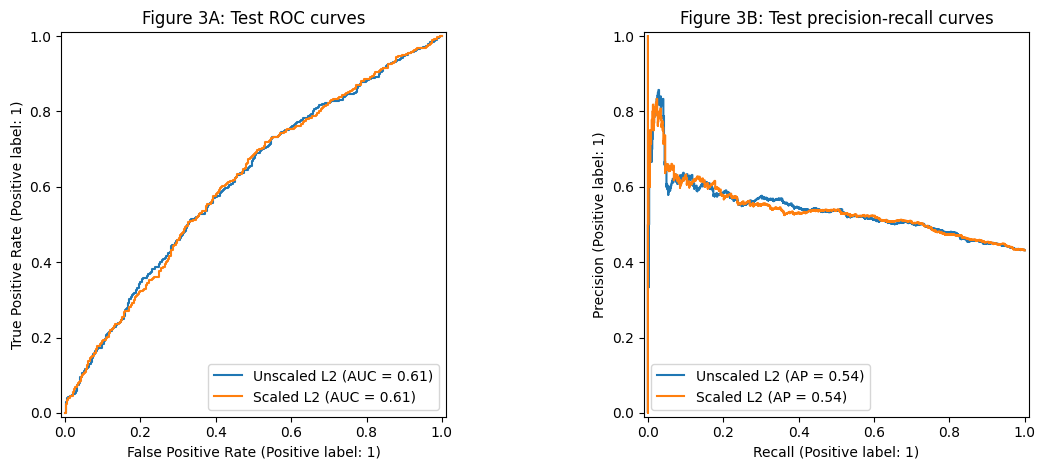

In [5]:
def score_model(label,model):
    prob=model.predict_proba(X_test)[:,1]
    pred=(prob>=.5).astype(int)
    return {'Model':label,'Accuracy':accuracy_score(y_test,pred),'Balanced accuracy':balanced_accuracy_score(y_test,pred),
            'Precision':precision_score(y_test,pred,zero_division=0),'Recall':recall_score(y_test,pred,zero_division=0),
            'F1':f1_score(y_test,pred,zero_division=0),'ROC-AUC':roc_auc_score(y_test,prob),
            'Average precision':average_precision_score(y_test,prob),'Brier loss':brier_score_loss(y_test,prob)}
results=pd.DataFrame([score_model(name,model) for name,model in tuned.items()]).set_index('Model')
print('Positive label: worldwide revenue >= 2x production budget')
print('Evaluation threshold: 0.50')
print(results.round(4).to_string())
fig,ax=plt.subplots(1,2,figsize=(12,4.8))
for name,model in tuned.items():
    RocCurveDisplay.from_estimator(model,X_test,y_test,ax=ax[0],name=name)
    PrecisionRecallDisplay.from_estimator(model,X_test,y_test,ax=ax[1],name=name)
ax[0].set_title('Figure 3A: Test ROC curves')
ax[1].set_title('Figure 3B: Test precision-recall curves')
plt.tight_layout();plt.show()

## 6. Interpret standardized coefficients and odds ratios

Largest magnitude standardized coefficients:
              Scaled coefficient  Odds ratio per 1 SD
budget_m                   0.175                1.191
genre_drama               -0.175                0.840
runtime                    0.139                1.149
month_6                    0.105                1.111
month_9                   -0.105                0.901
genre_horror               0.102                1.108
genre_action              -0.099                0.906
release_year              -0.082                0.922
genre_comedy               0.079                1.082
month_10                  -0.077                0.926
month_7                    0.067                1.069
month_8                   -0.046                0.955


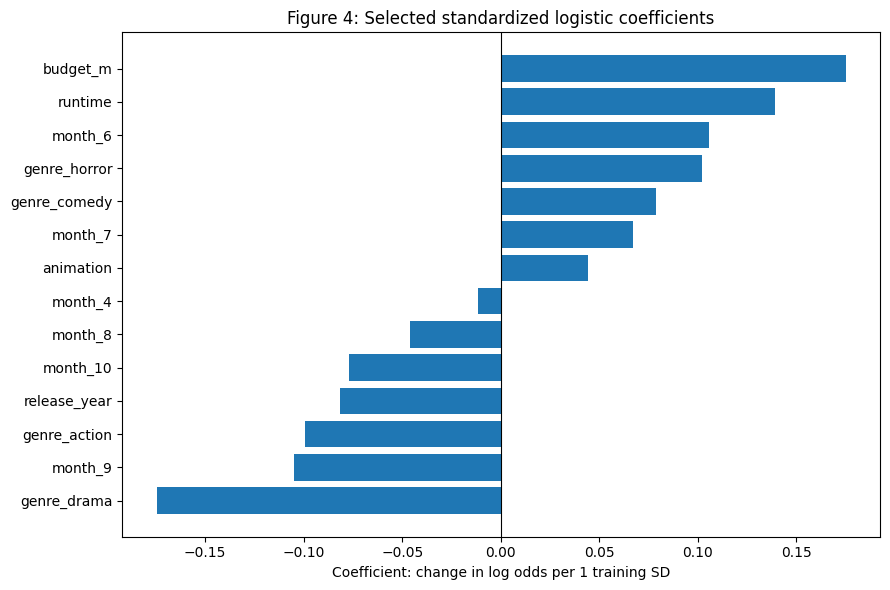

In [6]:
scaled=tuned['Scaled L2']
coeff=pd.Series(scaled.named_steps['clf'].coef_[0],index=features).sort_values()
coefs=pd.DataFrame({'Scaled coefficient':coeff,'Odds ratio per 1 SD':np.exp(coeff)})
print('Largest magnitude standardized coefficients:')
print(coefs.reindex(coeff.abs().sort_values(ascending=False).index).head(12).round(3).to_string())
show=pd.concat([coeff.head(7),coeff.tail(7)]).sort_values()
fig,ax=plt.subplots(figsize=(9,6))
ax.barh(show.index,show.values)
ax.axvline(0,color='black',linewidth=.8)
ax.set(title='Figure 4: Selected standardized logistic coefficients',xlabel='Coefficient: change in log odds per 1 training SD')
plt.tight_layout();plt.show()

## 7. Confusion matrix and calibration

Confusion matrix: rows are actual classes and columns predicted classes
[[636 169]
 [410 201]]


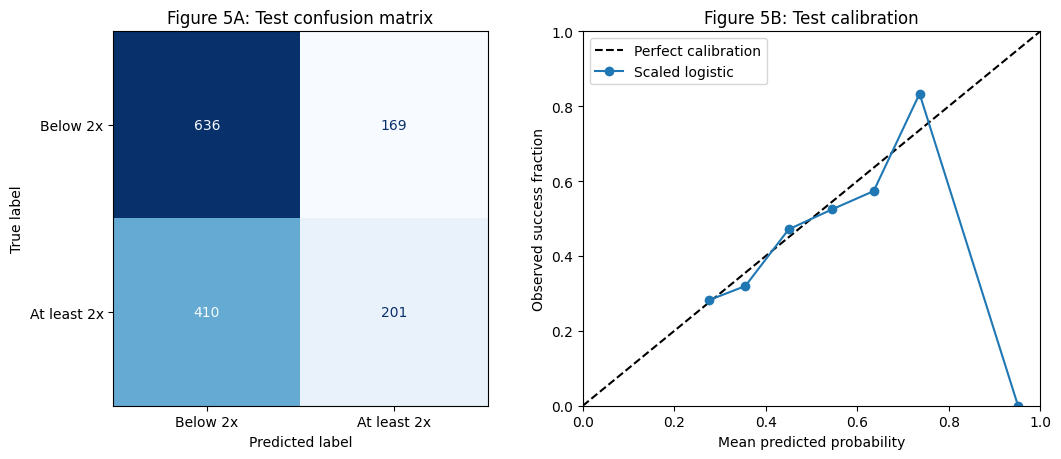

Calibration bin counts: [85, 441, 520, 282, 75, 12, 1]


In [7]:
model=tuned['Scaled L2']
p=model.predict_proba(X_test)[:,1]
pred=(p>=.5).astype(int)
cm=confusion_matrix(y_test,pred,labels=[0,1])
print('Confusion matrix: rows are actual classes and columns predicted classes')
print(cm)
bins=pd.DataFrame({'prob':p,'actual':y_test.to_numpy()})
bins['bin']=pd.cut(bins.prob,np.linspace(0,1,11),include_lowest=True)
cal=bins.groupby('bin',observed=False).agg(mean_prediction=('prob','mean'),observed_fraction=('actual','mean'),count=('actual','size')).dropna()
fig,axs=plt.subplots(1,2,figsize=(11,4.7))
ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=['Below 2x','At least 2x']).plot(ax=axs[0],colorbar=False,cmap='Blues')
axs[0].set_title('Figure 5A: Test confusion matrix')
axs[1].plot([0,1],[0,1],linestyle='--',color='black',label='Perfect calibration')
axs[1].plot(cal.mean_prediction,cal.observed_fraction,'o-',label='Scaled logistic')
axs[1].set(xlim=(0,1),ylim=(0,1),xlabel='Mean predicted probability',ylabel='Observed success fraction',title='Figure 5B: Test calibration')
axs[1].legend();plt.tight_layout();plt.show()
print('Calibration bin counts:',cal['count'].to_list())

## 8. Overfitting checks and sensitivity analysis

In [8]:
for label,model in tuned.items():
    train_auc=roc_auc_score(y_train,model.predict_proba(X_train)[:,1])
    test_auc=results.loc[label,'ROC-AUC']
    print(f'{label}: training ROC-AUC={train_auc:.3f}; test ROC-AUC={test_auc:.3f}; train minus test={train_auc-test_auc:+.3f}')
print('Uninformed always-positive accuracy:',round(y_test.mean(),3))
print('Uninformed majority-class accuracy:',round(max(y_test.mean(),1-y_test.mean()),3))
print('Always-positive average precision baseline:',round(y_test.mean(),3))

Unscaled L2: training ROC-AUC=0.617; test ROC-AUC=0.614; train minus test=+0.003
Scaled L2: training ROC-AUC=0.619; test ROC-AUC=0.614; train minus test=+0.006
Uninformed always-positive accuracy: 0.431
Uninformed majority-class accuracy: 0.569
Always-positive average precision baseline: 0.431


## 9. Conclusions for the Week 7 Milestone One report

In [9]:
best_auc_name=results['ROC-AUC'].idxmax()
print(f'Analytical sample: {len(df):,} movies, with {int(df.success.sum()):,} meeting the defined >=2x gross-to-budget threshold.')
for name,row in results.iterrows():
    print(f'{name}: accuracy={row["Accuracy"]:.3f}; ROC-AUC={row["ROC-AUC"]:.3f}; average precision={row["Average precision"]:.3f}; F1={row["F1"]:.3f}; Brier loss={row["Brier loss"]:.3f}.')
print('Highest held-out ROC-AUC:',best_auc_name)
print('Scaling comparison in ROC-AUC:',round(results.loc['Scaled L2','ROC-AUC']-results.loc['Unscaled L2','ROC-AUC'],4))
print('Largest standardized coefficient:',coefs['Scaled coefficient'].abs().idxmax())
print('Interpretation: This comparison evaluates classification of the specified gross-to-budget outcome, not accounting profit or earlier continuous-revenue model performance.')

Analytical sample: 7,079 movies, with 3,087 meeting the defined >=2x gross-to-budget threshold.
Unscaled L2: accuracy=0.603; ROC-AUC=0.614; average precision=0.538; F1=0.425; Brier loss=0.236.
Scaled L2: accuracy=0.591; ROC-AUC=0.614; average precision=0.538; F1=0.410; Brier loss=0.236.
Highest held-out ROC-AUC: Unscaled L2
Scaling comparison in ROC-AUC: -0.0004
Largest standardized coefficient: budget_m
Interpretation: This comparison evaluates classification of the specified gross-to-budget outcome, not accounting profit or earlier continuous-revenue model performance.
